# Mission 5 — Voix du client et NLP
**TP Customer Intelligence & AI Marketing Strategy — cas NovaMarket**

**Objectif :** explorer les 700 avis clients, les classer en positif / neutre / négatif avec un lexique simple, comparer ce classement à une lecture humaine, identifier les irritants récurrents et proposer des actions correctives.

**Plan**

0. Mise en place
1. Exploration des avis
2. Le lexique de sentiment
3. Classification automatique
4. Comparaison avec une lecture manuelle
5. Thèmes et irritants
6. Lien avec le comportement des clients
7. Actions correctives
8. Limites de l'approche par lexique
9. Export de `sentiment_summary.csv`

## 0. Mise en place

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_NovaMarket'
except ImportError:
    BASE = os.environ.get('TP_BASE', '..')

DATA = os.path.join(BASE, 'data')
OUT = os.path.join(BASE, 'outputs')
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
COULEURS_SENT = {'positif': '#2E7D32', 'neutre': '#90A4AE', 'négatif': '#C62828'}

## 1. Exploration des avis

In [2]:
avis = pd.read_csv(os.path.join(DATA, 'reviews.csv'), parse_dates=['date'])
print(f"{len(avis)} avis, laissés par {avis['customer_id'].nunique()} clients, "
      f"du {avis['date'].min():%d/%m/%Y} au {avis['date'].max():%d/%m/%Y}")
print(f"Nombre de textes différents : {avis['review_text'].nunique()}")
print('Nombre d\'avis par client :', avis.groupby('customer_id').size().value_counts().sort_index().to_dict())

frequences = avis['review_text'].value_counts().to_frame('nb_avis')
frequences['part_%'] = (frequences['nb_avis'] / len(avis) * 100).round(1)
frequences

700 avis, laissés par 562 clients, du 01/01/2025 au 31/12/2025
Nombre de textes différents : 10
Nombre d'avis par client : {1: 441, 2: 108, 3: 9, 4: 4}


,nb_avis,part_%
review_text,,
J'adore cette marque et les nouveautés,88,12.6
Conforme à mes attentes,76,10.9
Commande incomplète et remboursement compliqué,75,10.7
"Produit correct, sans plus",74,10.6
"Service client très réactif, expérience parfaite",70,10.0
Bon rapport qualité prix,70,10.0
"Colis arrivé en retard, expérience frustrante",68,9.7
"Très bon produit, livraison rapide et je recommande",62,8.9
"Déçu par la qualité, je ne rachèterai pas",59,8.4


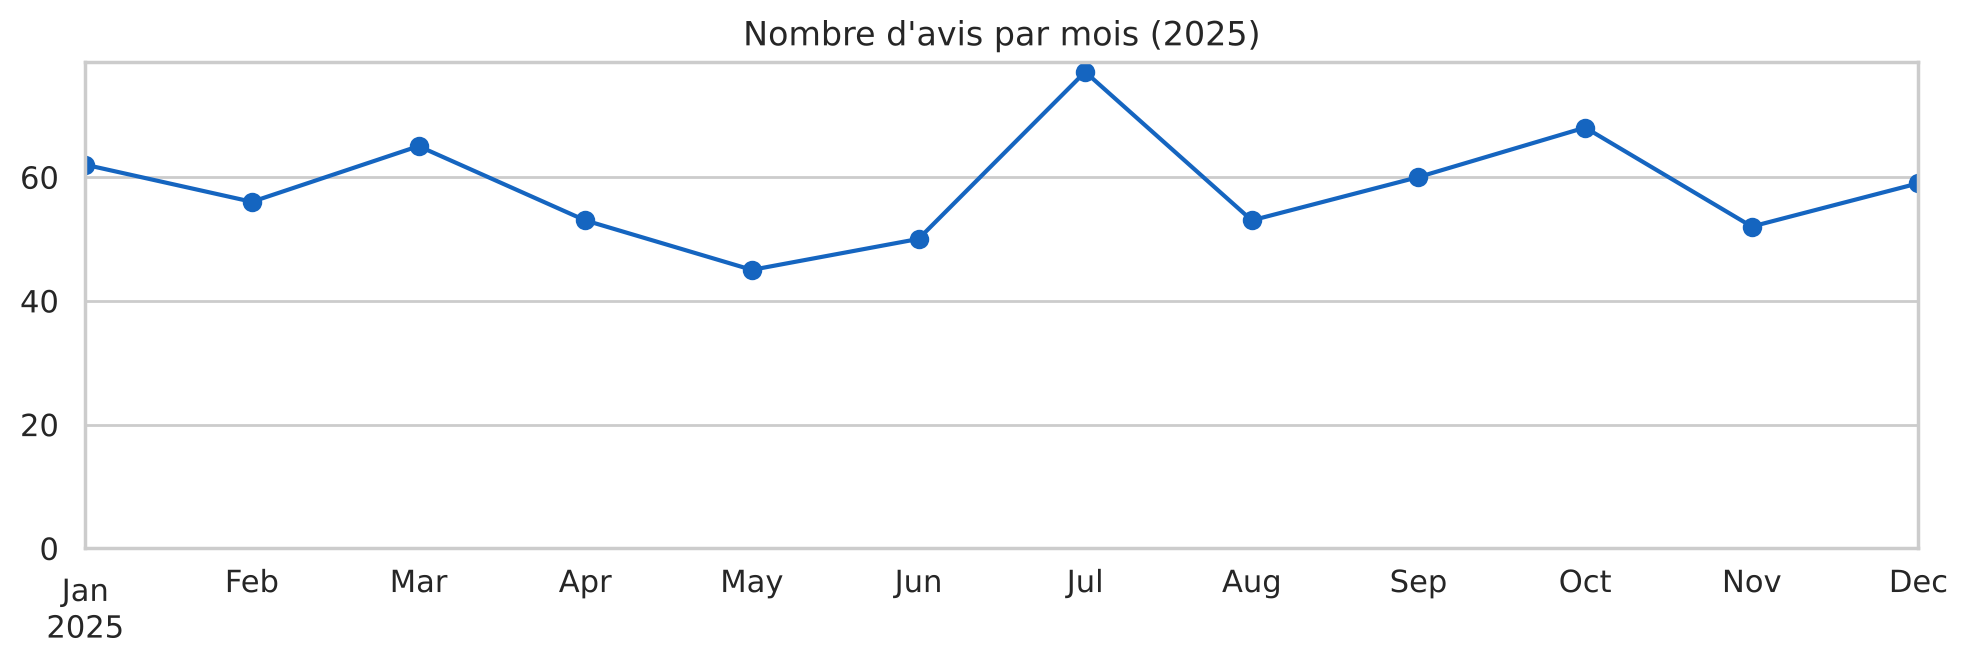

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
avis.set_index('date').resample('ME').size().plot(ax=ax, marker='o', color='#1565C0')
ax.set_title("Nombre d'avis par mois (2025)"); ax.set_xlabel(''); ax.set_ylim(0)
plt.tight_layout(); plt.show()

**Constat :** les 700 avis ne contiennent que **10 phrases différentes**, chacune répétée entre 58 et 88 fois. Le volume est régulier sur l'année (environ 60 avis par mois). Dans une vraie base, chaque avis serait unique : c'est la première limite de ce jeu de données synthétique.

## 2. Le lexique de sentiment
On définit deux listes de mots : **positifs** et **négatifs**. Le score d'un avis est :

**score = nombre de mots positifs − nombre de mots négatifs**

- score > 0 → **positif**
- score < 0 → **négatif**
- score = 0 → **neutre**

Le lexique est volontairement simple. On y a mis le mot « correct » comme positif, comme le ferait un lexique générique, pour voir ce que cela donne.

In [4]:
MOTS_POSITIFS = {'adore', 'aime', 'parfait', 'parfaite', 'recommande', 'rapide', 'bon', 'bonne', 'très bon',
                 'réactif', 'réactive', 'excellent', 'super', 'top', 'correct', 'satisfait', 'ravi', 'ravie'}
MOTS_NEGATIFS = {'déçu', 'déçue', 'retard', 'frustrant', 'frustrante', 'compliqué', 'compliquée',
                 'incomplète', 'incomplet', 'problème', 'cassé', 'abîmé', 'lent', 'mauvais', 'mauvaise', 'nul'}

def mots(texte):
    """Découpe un texte en mots en minuscules (les apostrophes séparent : j'adore → j, adore)."""
    return re.findall(r"[a-zàâäçéèêëîïôöùûüœ]+", texte.lower())

def score_sentiment(texte):
    m = mots(texte)
    pos = [w for w in m if w in MOTS_POSITIFS]
    neg = [w for w in m if w in MOTS_NEGATIFS]
    return len(pos) - len(neg), pos, neg

def classe(score):
    return 'positif' if score > 0 else ('négatif' if score < 0 else 'neutre')

print(mots("J'adore cette marque et les nouveautés"))

['j', 'adore', 'cette', 'marque', 'et', 'les', 'nouveautés']


## 3. Classification automatique

In [5]:
resultats = avis['review_text'].apply(score_sentiment)
avis['score_lexique'] = resultats.str[0]
avis['mots_positifs'] = resultats.str[1].str.join(', ')
avis['mots_negatifs'] = resultats.str[2].str.join(', ')
avis['sentiment_lexique'] = avis['score_lexique'].apply(classe)

# Détail par texte (10 phrases)
(avis.groupby('review_text')[['score_lexique', 'mots_positifs', 'mots_negatifs', 'sentiment_lexique']].first()
 .join(frequences['nb_avis']).sort_values('score_lexique', ascending=False))

,score_lexique,mots_positifs,mots_negatifs,sentiment_lexique,nb_avis
review_text,,,,,
"Très bon produit, livraison rapide et je recommande",3,"bon, rapide, recommande",,positif,62
"Service client très réactif, expérience parfaite",2,"réactif, parfaite",,positif,70
J'adore cette marque et les nouveautés,1,adore,,positif,88
Bon rapport qualité prix,1,bon,,positif,70
"Produit correct, sans plus",1,correct,,positif,74
Conforme à mes attentes,0,,,neutre,76
La navigation du site est compliquée,-1,,compliquée,négatif,58
"Déçu par la qualité, je ne rachèterai pas",-1,,déçu,négatif,59
"Colis arrivé en retard, expérience frustrante",-2,,"retard, frustrante",négatif,68


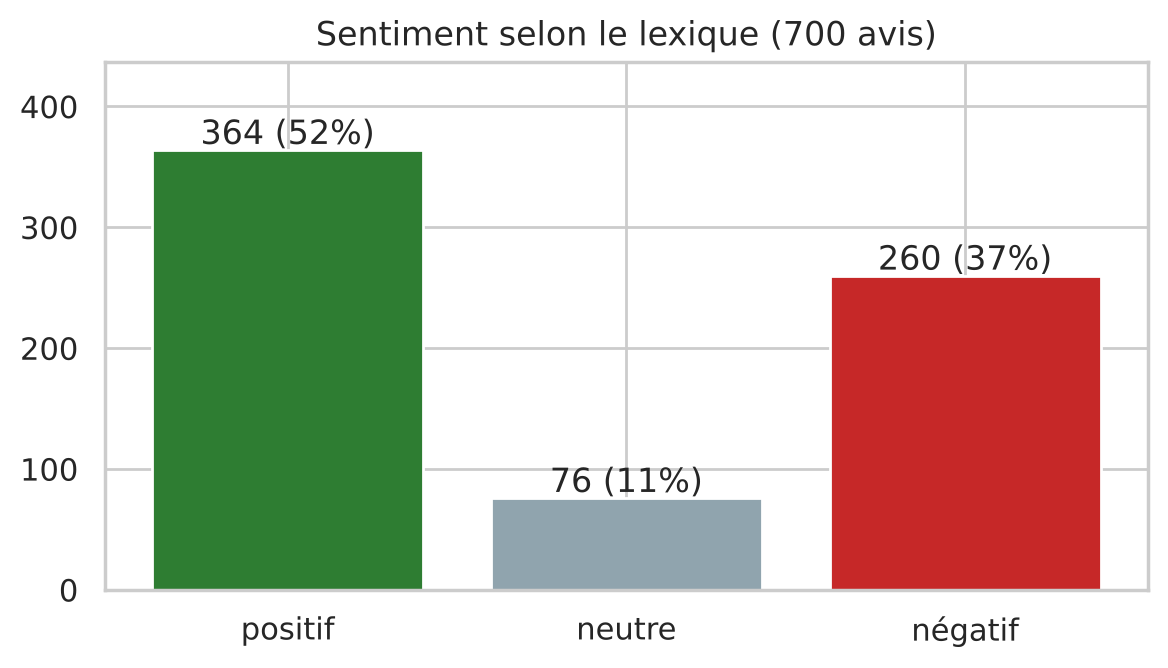

In [6]:
repartition = avis['sentiment_lexique'].value_counts().reindex(['positif', 'neutre', 'négatif'])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(repartition.index, repartition.values, color=[COULEURS_SENT[s] for s in repartition.index])
for i, v in enumerate(repartition.values):
    ax.text(i, v + 5, f'{v} ({v / len(avis):.0%})', ha='center')
ax.set_title('Sentiment selon le lexique (700 avis)'); ax.set_ylim(0, repartition.max() * 1.2)
plt.tight_layout(); plt.show()

## 4. Comparaison avec une lecture manuelle
**Méthode :** on tire au hasard un **échantillon de 50 avis** et on les étiquette à la main, en lisant le texte comme le ferait un humain. Comme il n'existe que 10 phrases, la lecture manuelle revient à juger chacune d'elles une fois. On compare ensuite cette « vérité humaine » au lexique.

| Texte | Lecture manuelle | Justification |
|---|---|---|
| J'adore cette marque et les nouveautés | positif | Enthousiasme explicite |
| Très bon produit, livraison rapide et je recommande | positif | Satisfaction et recommandation |
| Service client très réactif, expérience parfaite | positif | Éloge du service |
| Bon rapport qualité prix | positif | Jugement favorable |
| Conforme à mes attentes | neutre | Ni plainte ni enthousiasme |
| Produit correct, sans plus | **neutre** | « sans plus » annule « correct » : avis tiède |
| Colis arrivé en retard, expérience frustrante | négatif | Plainte sur la livraison |
| Commande incomplète et remboursement compliqué | négatif | Double plainte |
| Déçu par la qualité, je ne rachèterai pas | négatif | Déception + intention de partir |
| La navigation du site est compliquée | négatif | Plainte sur le site |

Accord lexique / lecture manuelle sur l'échantillon de 50 avis : 96%
Accord sur l'ensemble des 700 avis : 89%


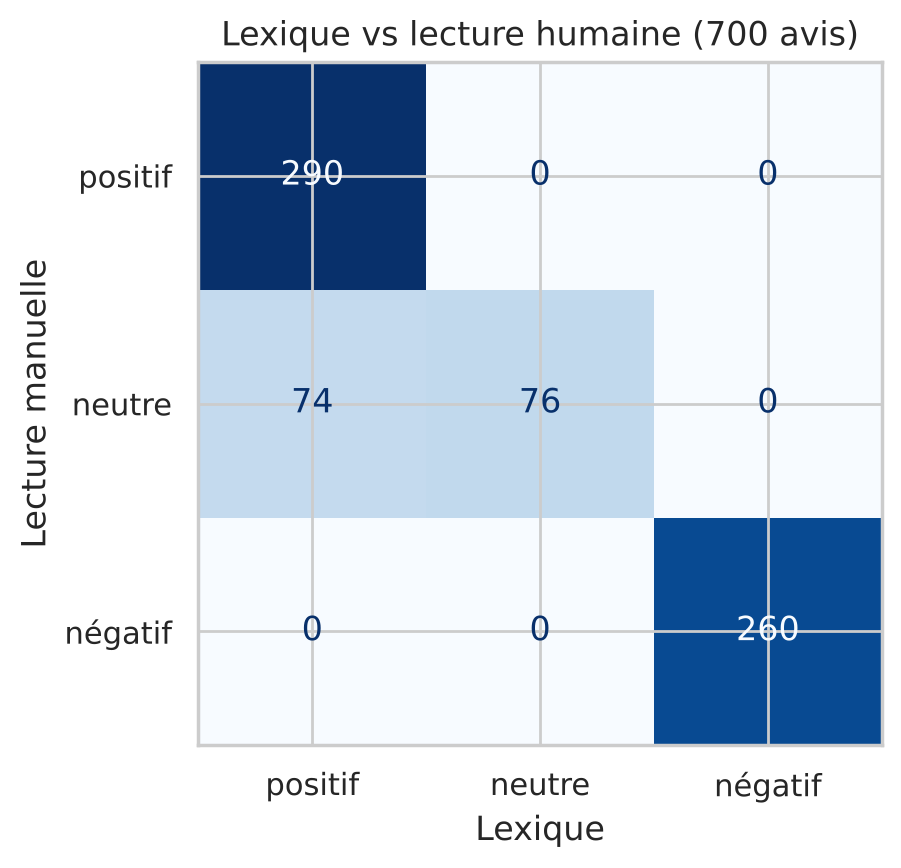

In [7]:
LECTURE_MANUELLE = {
    "J'adore cette marque et les nouveautés": 'positif',
    'Très bon produit, livraison rapide et je recommande': 'positif',
    'Service client très réactif, expérience parfaite': 'positif',
    'Bon rapport qualité prix': 'positif',
    'Conforme à mes attentes': 'neutre',
    'Produit correct, sans plus': 'neutre',
    'Colis arrivé en retard, expérience frustrante': 'négatif',
    'Commande incomplète et remboursement compliqué': 'négatif',
    'Déçu par la qualité, je ne rachèterai pas': 'négatif',
    'La navigation du site est compliquée': 'négatif',
}
avis['sentiment_manuel'] = avis['review_text'].map(LECTURE_MANUELLE)

echantillon = avis.sample(50, random_state=RANDOM_STATE)
accord_ech = accuracy_score(echantillon['sentiment_manuel'], echantillon['sentiment_lexique'])
accord_total = accuracy_score(avis['sentiment_manuel'], avis['sentiment_lexique'])
print(f"Accord lexique / lecture manuelle sur l'échantillon de 50 avis : {accord_ech:.0%}")
print(f"Accord sur l'ensemble des 700 avis : {accord_total:.0%}")

ordre = ['positif', 'neutre', 'négatif']
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(avis['sentiment_manuel'], avis['sentiment_lexique'], labels=ordre),
                       display_labels=ordre).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_xlabel('Lexique'); ax.set_ylabel('Lecture manuelle'); ax.set_title('Lexique vs lecture humaine (700 avis)')
plt.tight_layout(); plt.show()

In [8]:
# Les avis où le lexique se trompe
erreurs = avis[avis['sentiment_manuel'] != avis['sentiment_lexique']]
erreurs.groupby('review_text').agg(nb_avis=('review_id', 'size'), lexique=('sentiment_lexique', 'first'),
                                   lecture_manuelle=('sentiment_manuel', 'first'), mots_detectes=('mots_positifs', 'first'))

,nb_avis,lexique,lecture_manuelle,mots_detectes
review_text,,,,
"Produit correct, sans plus",74,positif,neutre,correct


**Constat :**
- Sur l'échantillon de 50 avis, le lexique est d'accord avec la lecture humaine pour **48 avis (96 %)**.
- Sur l'ensemble, il est d'accord sur **9 phrases sur 10**, soit environ 89 % des avis.
- Un petit échantillon peut donc sembler meilleur que la réalité : il faut lire assez d'avis pour juger un outil.
- **La seule erreur est « Produit correct, sans plus » (74 avis).** Le lexique voit « correct » et classe l'avis en positif. Un humain comprend que « sans plus » en fait un avis **tiède**, presque une déception.
- Le lexique **ne comprend pas le sens d'une expression**, il compte des mots. L'erreur est discrète ici, mais elle **gonfle artificiellement la part d'avis positifs**.

## 5. Thèmes et irritants
On rattache chaque avis à un ou plusieurs **thèmes** grâce à des mots-clés, puis on croise thèmes et sentiment. Un **irritant** est un thème associé à des avis négatifs.

In [9]:
THEMES = {
    'Livraison': ['colis', 'livraison', 'retard'],
    'Commande & remboursement': ['commande', 'incomplète', 'remboursement'],
    'Qualité produit': ['qualité', 'produit'],
    'Site & navigation': ['site', 'navigation'],
    'Service client': ['service'],
    'Prix': ['prix'],
    'Marque & nouveautés': ['marque', 'nouveautés'],
}

def themes(texte):
    m = set(mots(texte))
    trouves = [t for t, cles in THEMES.items() if m & set(cles)]
    return trouves if trouves else ['Général (sans thème)']

avis['themes'] = avis['review_text'].apply(themes)
avis_themes = avis.explode('themes').reset_index(drop=True)

croisement = (pd.crosstab(avis_themes['themes'], avis_themes['sentiment_manuel'])
              .reindex(columns=ordre, fill_value=0))
croisement['total'] = croisement.sum(axis=1)
croisement['part_négatif_%'] = (croisement['négatif'] / croisement['total'] * 100).round(0)
croisement.sort_values('négatif', ascending=False)

sentiment_manuel,positif,neutre,négatif,total,part_négatif_%
themes,,,,,
Commande & remboursement,0,0,75,75,100.0
Livraison,62,0,68,130,52.0
Qualité produit,132,74,59,265,22.0
Site & navigation,0,0,58,58,100.0
Marque & nouveautés,88,0,0,88,0.0
Général (sans thème),0,76,0,76,0.0
Prix,70,0,0,70,0.0
Service client,70,0,0,70,0.0


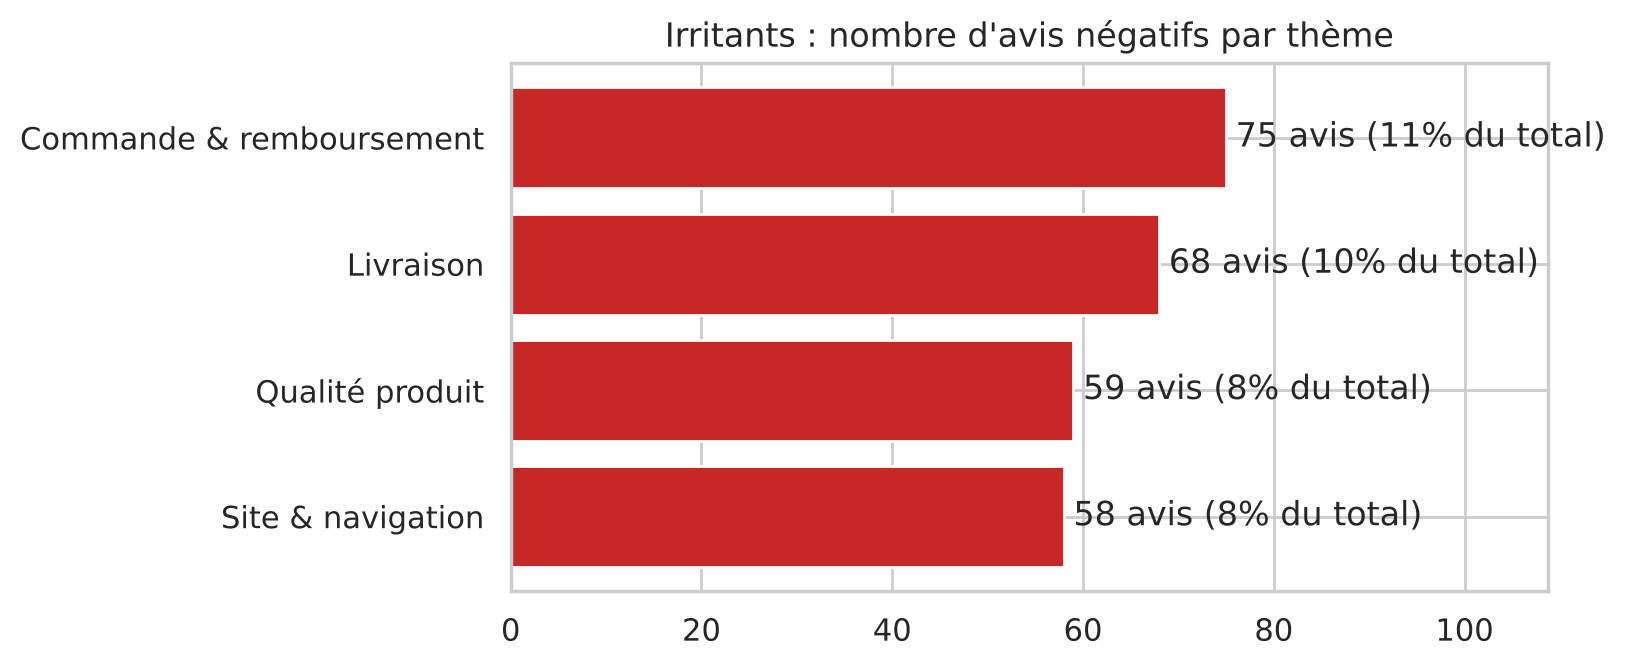

In [10]:
irritants = croisement[croisement['négatif'] > 0].sort_values('négatif')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(irritants.index, irritants['négatif'], color='#C62828')
for i, v in enumerate(irritants['négatif']):
    ax.text(v + 1, i, f'{v} avis ({v / len(avis):.0%} du total)', va='center')
ax.set_title('Irritants : nombre d\'avis négatifs par thème'); ax.set_xlim(0, irritants['négatif'].max() * 1.45)
plt.tight_layout(); plt.show()

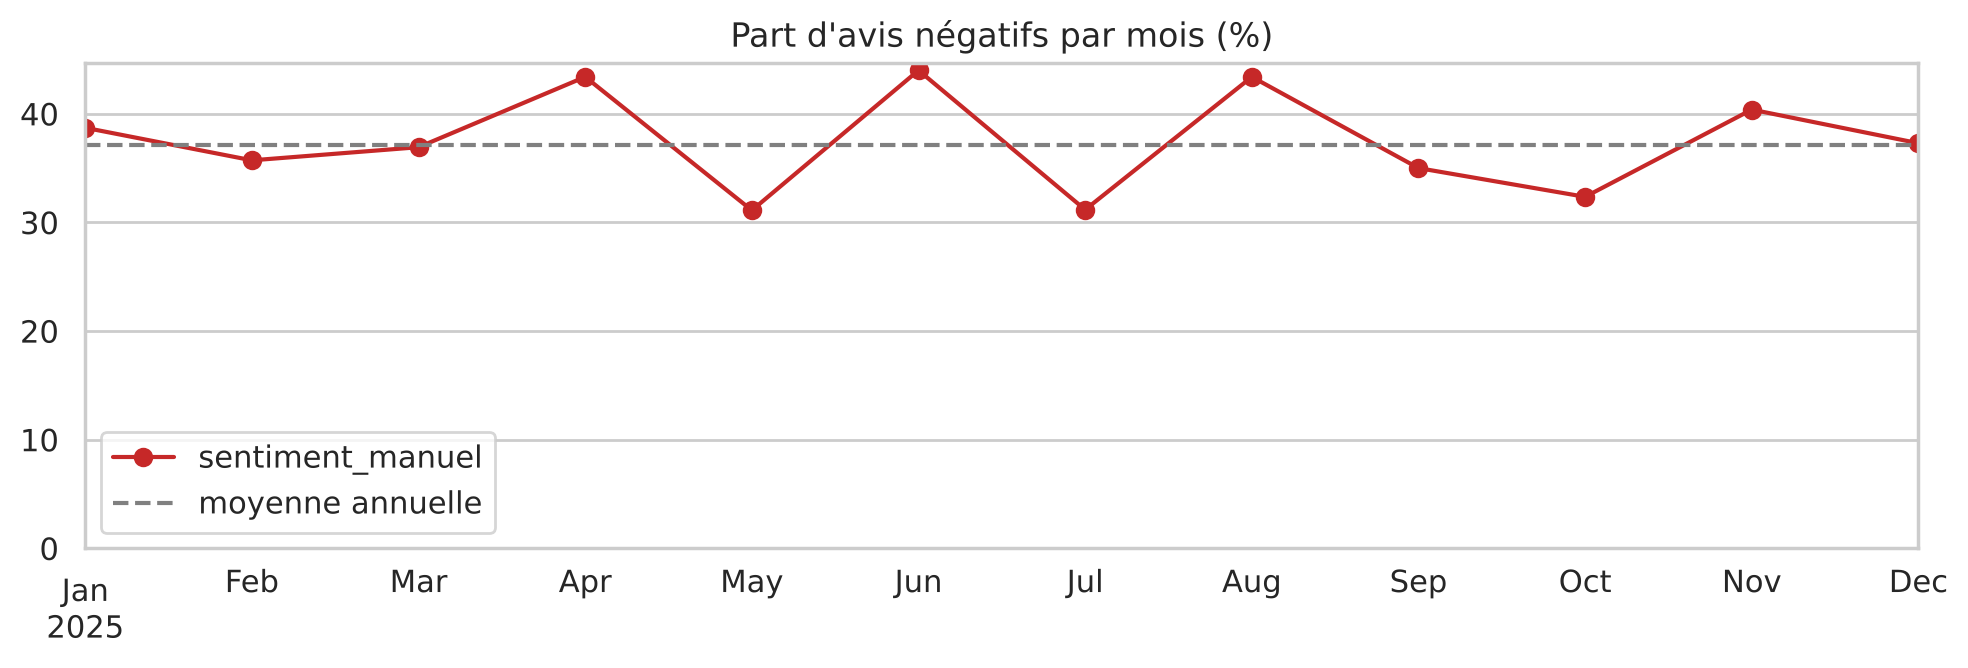

In [11]:
# Évolution mensuelle de la part d'avis négatifs
mensuel = (avis.set_index('date').resample('ME')['sentiment_manuel']
           .apply(lambda s: (s == 'négatif').mean() * 100))
fig, ax = plt.subplots(figsize=(10, 3.5))
mensuel.plot(ax=ax, marker='o', color='#C62828')
ax.axhline((avis['sentiment_manuel'] == 'négatif').mean() * 100, ls='--', color='grey', label='moyenne annuelle')
ax.set_title("Part d'avis négatifs par mois (%)"); ax.set_xlabel(''); ax.set_ylim(0); ax.legend()
plt.tight_layout(); plt.show()

**Constat :** environ **37 % des avis sont négatifs** (lecture manuelle). Ils se répartissent sur **4 irritants de poids comparable** :

1. **Commande & remboursement**, en tête : « Commande incomplète et remboursement compliqué ». C'est un double problème, logistique puis service après-vente.
2. **Livraison** : « Colis arrivé en retard ». Le thème est aussi cité positivement (« livraison rapide »), donc l'expérience est **inégale**.
3. **Qualité produit** : « Déçu par la qualité, je ne rachèterai pas ». C'est l'avis le plus grave, car il annonce explicitement le départ.
4. **Site & navigation** : « La navigation du site est compliquée ».

**Points forts :** l'attachement à la **marque et aux nouveautés** (l'avis le plus fréquent), le **service client** quand il intervient, et le **rapport qualité-prix**.

La part d'avis négatifs varie d'un mois à l'autre sans tendance nette. Il n'y a pas de dégradation ponctuelle à expliquer.

## 6. Lien avec le comportement des clients
On relie chaque avis au client qui l'a écrit (`customer_id`) pour voir si le sentiment exprimé se retrouve dans le churn et la satisfaction déclarée.

In [12]:
clients = pd.read_csv(os.path.join(OUT, 'customers_prepared.csv'))[['customer_id', 'churn_90d', 'satisfaction_score', 'support_tickets_90d']]
segments = pd.read_csv(os.path.join(OUT, 'customer_segments.csv'))[['customer_id', 'segment']]
avis = avis.merge(clients, on='customer_id', how='left').merge(segments, on='customer_id', how='left')

lien = avis.groupby('sentiment_manuel').agg(
    nb_avis=('review_id', 'size'),
    taux_churn_pct=('churn_90d', 'mean'),
    satisfaction_moyenne=('satisfaction_score', 'mean'),
    tickets_moyens=('support_tickets_90d', 'mean'),
).reindex(ordre)
lien['taux_churn_pct'] *= 100
print(f"Taux de churn de toute la base : {clients['churn_90d'].mean():.1%}")
lien.round(2)

Taux de churn de toute la base : 23.2%


,nb_avis,taux_churn_pct,satisfaction_moyenne,tickets_moyens
sentiment_manuel,,,,
positif,290,19.31,3.85,0.84
neutre,150,28.67,3.73,1.04
négatif,260,26.54,3.74,0.95


In [13]:
par_texte = avis.groupby('review_text').agg(
    nb_avis=('review_id', 'size'), sentiment=('sentiment_manuel', 'first'),
    taux_churn_pct=('churn_90d', 'mean'), satisfaction_moyenne=('satisfaction_score', 'mean'))
par_texte['taux_churn_pct'] *= 100
par_texte.sort_values('taux_churn_pct', ascending=False).round(2)

,nb_avis,sentiment,taux_churn_pct,satisfaction_moyenne
review_text,,,,
Commande incomplète et remboursement compliqué,75,négatif,32.00,3.70
Conforme à mes attentes,76,neutre,31.58,3.76
La navigation du site est compliquée,58,négatif,27.59,3.72
"Produit correct, sans plus",74,neutre,25.68,3.70
"Colis arrivé en retard, expérience frustrante",68,négatif,25.00,3.64
"Très bon produit, livraison rapide et je recommande",62,positif,20.97,3.86
"Déçu par la qualité, je ne rachèterai pas",59,négatif,20.34,3.95
Bon rapport qualité prix,70,positif,20.00,3.72
"Service client très réactif, expérience parfaite",70,positif,20.00,3.79


In [14]:
print('Répartition des avis par segment (% en ligne) :')
(pd.crosstab(avis['segment'], avis['sentiment_manuel'], normalize='index') * 100).reindex(columns=ordre).round(0)

Répartition des avis par segment (% en ligne) :


sentiment_manuel,positif,neutre,négatif
segment,,,
En décrochage,35.0,22.0,43.0
Fidèles premium,41.0,18.0,40.0
Nouveaux à activer,42.0,21.0,36.0
Occasionnels récents,40.0,28.0,31.0
Réguliers satisfaits,47.0,18.0,35.0


**Constat :**
- **Les clients qui laissent un avis négatif ou neutre partent un peu plus** que ceux qui laissent un avis positif : environ 27-29 % de churn contre 19 %, pour 23 % sur toute la base.
- Les textes les plus liés au départ sont :
    - « Commande incomplète et remboursement compliqué » : 32 % de churn ;
    - « Conforme à mes attentes » : 32 % ;
    - « La navigation du site est compliquée » : 28 %.
- **Les avis tièdes sont aussi un signal d'alerte.** Un client « sans plus » n'a pas de raison forte de rester.
- **Le lien reste faible et doit être lu avec prudence :**
    - environ 60 à 90 avis par phrase, c'est peu, et les écarts peuvent venir du hasard ;
    - la **satisfaction déclarée** est presque identique quel que soit le texte. Par exemple, l'avis « Déçu par la qualité, je ne rachèterai pas » vient de clients notés en moyenne près de 4/5, et leur churn n'est pas plus élevé.
- **Les textes semblent avoir été attribués de façon presque aléatoire** aux clients. C'est une limite majeure du jeu synthétique : dans une vraie base, un avis négatif serait beaucoup plus prédictif du départ.

**Décision :** les avis servent ici à **identifier les irritants et à les corriger**, pas à prédire le churn. Le sentiment n'est donc pas ajouté au modèle de la mission 4.

## 7. Actions correctives
Chaque action est reliée à un **constat** (étape 5), à un **objectif** de la note de cadrage et à un **KPI**.

| Irritant | Constat | Action corrective | Responsable | Objectif | KPI |
|---|---|---|---|---|---|
| **Commande incomplète & remboursement** | 75 avis (11 %), churn d'environ 32 % chez ces clients | Contrôle de préparation des colis (double vérification), remboursement en 1 clic depuis l'espace client, renvoi automatique de l'article manquant | Logistique + service client | O1 | Taux de commandes incomplètes, délai de remboursement, churn des clients concernés |
| **Retards de livraison** | 68 avis (10 %) | Suivi de colis proactif (SMS en cas de retard), geste commercial automatique au-delà de X jours, revue des transporteurs | Logistique + CRM | O1 | Taux de livraison à l'heure, avis négatifs sur la livraison |
| **Qualité produit** | 59 avis (8 %), intention explicite de ne pas racheter | Remonter les produits concernés au sourcing, contacter le client sous 48 h, échange ou avoir | Produit + service client | O1 | Taux de retour par produit, note moyenne produit |
| **Navigation du site** | 58 avis (8 %), churn d'environ 28 % | Test utilisateur sur le parcours d'achat, simplification du menu et de la recherche, suivi des abandons de panier | E-commerce / UX | O3 | Taux de conversion du site, abandon de panier |
| **Avis tièdes** (« Conforme à mes attentes », « Produit correct, sans plus ») | 150 avis (21 %), churn d'environ 29 % ; 74 d'entre eux classés à tort en positif par le lexique | Enquête courte après achat pour comprendre ce qui manque ; contenus conseils d'utilisation ; recommandation personnalisée (mission 6) | CRM + contenu | O2 | Taux de réachat des clients « tièdes » |

**À capitaliser :** « J'adore la marque et les nouveautés » est l'avis le plus fréquent. Les lancements de nouveautés sont un levier fort pour les Fidèles premium (mission 3) et pour les contenus (mission 7).

## 8. Limites de l'approche par lexique

In [15]:
# Quelques phrases réalistes qui piègent le lexique
pieges = pd.DataFrame({'texte': [
    'Pas déçu du tout, je recommande',            # négation
    "Livraison pas rapide du tout",               # négation
    'Super, encore un colis en retard...',        # ironie
    'Pas mal ce sérum',                           # expression
    'Le produit est arrivé abimé',                # faute d'accent : « abimé » absent du lexique
    'Bof',                                         # mot hors lexique
]})
pieges['sentiment_lexique'] = pieges['texte'].apply(lambda t: classe(score_sentiment(t)[0]))
pieges['lecture_humaine'] = ['positif', 'négatif', 'négatif', 'positif', 'négatif', 'négatif']
pieges['correct ?'] = np.where(pieges['sentiment_lexique'] == pieges['lecture_humaine'], 'oui', 'NON')
pieges

,texte,sentiment_lexique,lecture_humaine,correct ?
0,"Pas déçu du tout, je recommande",neutre,positif,NON
1,Livraison pas rapide du tout,positif,négatif,NON
2,"Super, encore un colis en retard...",neutre,négatif,NON
3,Pas mal ce sérum,neutre,positif,NON
4,Le produit est arrivé abimé,neutre,négatif,NON
5,Bof,neutre,négatif,NON


- **Négation :** dans « pas déçu », le mot « déçu » est compté comme négatif. Le sens réel de la phrase est inversé.
- **Ironie et second degré :** « Super, encore un retard… » contient « super ».
- **Expressions et nuances :** « pas mal », « sans plus », « bof » ne sont pas compris.
- **Fautes, accents, argot, emojis** : un mot mal orthographié échappe au lexique.
- **Un seul score par avis :** un avis peut être positif sur le produit et négatif sur la livraison.
- **Le lexique est fait à la main :** il dépend de qui l'écrit et doit être adapté au secteur (en beauté, « léger » ou « gras » n'ont pas le même sens que dans la mode).
- **Ici, le jeu est artificiel :** avec 10 phrases, le lexique semble très performant. Sur de vrais avis, l'accord tomberait nettement.

**Pour aller plus loin :** un modèle de langue entraîné sur le français (type CamemBERT) ou un LLM comprend le contexte et la négation. Il faut alors **valider ses résultats sur un échantillon lu par un humain**, contrôler les biais et **ne pas envoyer de données personnelles** à un service externe sans cadre RGPD.

## 9. Export de `sentiment_summary.csv`

In [16]:
synthese = avis.groupby('review_text').agg(
    nb_avis=('review_id', 'size'),
    sentiment_lexique=('sentiment_lexique', 'first'),
    score_lexique=('score_lexique', 'first'),
    sentiment_manuel=('sentiment_manuel', 'first'),
    themes=('themes', lambda s: ' | '.join(s.iloc[0])),
    taux_churn_clients_pct=('churn_90d', lambda s: round(s.mean() * 100, 1)),
    satisfaction_moyenne=('satisfaction_score', lambda s: round(s.mean(), 2)),
).reset_index()
synthese.insert(2, 'part_avis_pct', (synthese['nb_avis'] / len(avis) * 100).round(1))
synthese['accord_lexique_manuel'] = np.where(synthese['sentiment_lexique'] == synthese['sentiment_manuel'], 'oui', 'non')
synthese = synthese.sort_values(['sentiment_manuel', 'nb_avis'], ascending=[True, False])
synthese.to_csv(os.path.join(OUT, 'sentiment_summary.csv'), index=False)

avis.drop(columns=['themes']).assign(themes=avis['themes'].str.join(' | ')).to_csv(
    os.path.join(OUT, 'reviews_scored.csv'), index=False)
print('sentiment_summary.csv :', synthese.shape, '| reviews_scored.csv :', avis.shape)
synthese

sentiment_summary.csv : (10, 10) | reviews_scored.csv : (700, 14)


,review_text,nb_avis,part_avis_pct,sentiment_lexique,score_lexique,sentiment_manuel,themes,taux_churn_clients_pct,satisfaction_moyenne,accord_lexique_manuel
3,Conforme à mes attentes,76,10.9,neutre,0,neutre,Général (sans thème),31.6,3.76,oui
7,"Produit correct, sans plus",74,10.6,positif,1,neutre,Qualité produit,25.7,3.70,non
2,Commande incomplète et remboursement compliqué,75,10.7,négatif,-2,négatif,Commande & remboursement,32.0,3.70,oui
1,"Colis arrivé en retard, expérience frustrante",68,9.7,négatif,-2,négatif,Livraison,25.0,3.64,oui
4,"Déçu par la qualité, je ne rachèterai pas",59,8.4,négatif,-1,négatif,Qualité produit,20.3,3.95,oui
6,La navigation du site est compliquée,58,8.3,négatif,-1,négatif,Site & navigation,27.6,3.72,oui
5,J'adore cette marque et les nouveautés,88,12.6,positif,1,positif,Marque & nouveautés,17.0,3.99,oui
0,Bon rapport qualité prix,70,10.0,positif,1,positif,Qualité produit | Prix,20.0,3.72,oui
8,"Service client très réactif, expérience parfaite",70,10.0,positif,2,positif,Service client,20.0,3.79,oui
9,"Très bon produit, livraison rapide et je recommande",62,8.9,positif,3,positif,Livraison | Qualité produit,21.0,3.86,oui


**Fichiers produits dans `outputs/` :**
- `sentiment_summary.csv` : synthèse par texte d'avis (sentiment lexique et manuel, thèmes, churn et satisfaction des clients). C'est le livrable attendu.
- `reviews_scored.csv` : les 700 avis avec leur score, leur sentiment et leurs thèmes.